In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import ImageGrid
import cv2
import numpy as np
import imutils
import random
import pickle

In [128]:
data_dir = Path.cwd() / ".." / "EnsembleA"
print(data_dir)
LABELS = ["Cercle2", "Cercle3", "Cercle4", "Cercle5", "Diamant2", "Diamant3", "Diamant4", "Diamant5", "Hexagone2", "Hexagone3", "Hexagone4", "Hexagone5", "Triangle2", "Triangle3", "Triangle4", "Triangle5"]

/home/mathd/LOG635-Labo2/Creation_Image_Dataset/../EnsembleA


## Choix du sous-ensemble B et redimensionnement des images

In [397]:
# Image resize
WIDTH = 160
HEIGHT = 120

# Dataset: this list will contain all the images
data_set = []

for first_level in data_dir.glob('*'):
    if first_level.is_dir() and not first_level.name.startswith('.'):
        for second_level in first_level.glob("*"):
            if second_level.is_dir() and not second_level.name.startswith('.'):
                label = Path(second_level).name
                if label in LABELS:
                    class_num = LABELS.index(label)
                    for file in second_level.glob("*.jpg"):
                        image = cv2.imread(str(file), cv2.IMREAD_GRAYSCALE)
                        data_set.append([image, class_num, label])

In [395]:
data_setB = []
for image in data_set:
    if image[1] in [0,3,4,7,8,11,12,15]:
        data_setB.append(image)

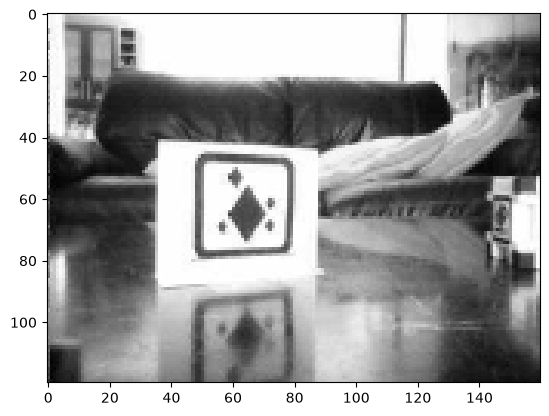

In [396]:
plt.imshow(data_setB[40][0], cmap="gray")

## Détection de la ROI

In [24]:
def detect_shape(contour):
    # initialize the shape name and approximate the contour
    shape = "unidentified"
    peri = cv2.arcLength(contour, True)
    approx = cv2.approxPolyDP(contour, 0.04 * peri, True)
    
    # if the shape is a triangle, it will have 3 vertices
    if len(approx) == 3:
        shape = "triangle"

    # if the shape has 4 vertices, it is either a square or
    # a rectangle
    elif len(approx) == 4:
        # compute the bounding box of the contour and use the
        # bounding box to compute the aspect ratio
        (x, y, w, h) = cv2.boundingRect(approx)
        ar = w / float(h)

        # a square will have an aspect ratio that is approximately
        # equal to one, otherwise, the shape is a rectangle
        shape = "square" if ar >= 0.95 and ar <= 1.05 else "diamond"

    # if the shape is a pentagon, it will have 5 vertices
    elif len(approx) == 5:
        shape = "hexagon"

    # otherwise, we assume the shape is a circle
    else:
        shape = "circle"

    # return the name of the shape
    return shape

In [408]:
import cv2
import numpy as np

# 1. Dimensions cibles standardisées pour chaque ROI
ROI_WIDTH = 64
ROI_HEIGHT = 64

data_setROI = []
nb_detectes = 0
nb_replis = 0

print(f"Extraction des ROI en cours sur {len(data_setB)} images...")

for idx, item in enumerate(data_setB):
    image_gray = item[0]
    class_num = item[1]
    label_name = item[2]
    h_img, w_img = image_gray.shape

    # Prétraitement et seuillage adaptatif
    blurred = cv2.GaussianBlur(image_gray, (3, 3), 0)
    thresh = cv2.adaptiveThreshold(
        blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 31, 3
    )
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
    thresh = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel, iterations=2)

    # Détection des contours avec arbre complet
    cnts, hierarchy = cv2.findContours(thresh.copy(), cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)

    candidats_marqueurs = []

    if hierarchy is not None and len(cnts) > 0:
        hier = hierarchy[0]

        for i, c in enumerate(cnts):
            x, y, w, h = cv2.boundingRect(c)
            box_area = float(w * h)

            # Rejeter les contours collés au bord et borner la taille du marqueur
            if x <= 1 or y <= 1 or (x + w) >= (w_img - 1) or (y + h) >= (h_img - 1):
                continue
            if w < 20 or h < 20 or w > 58 or h > 58:
                continue

            # Proportions strictement carrées (tolérance perspective)
            ar = w / float(h)
            if not (0.82 <= ar <= 1.22):
                continue

            # Approximation polygonale (4 à 8 sommets pour tolérer les coins arrondis)
            peri = cv2.arcLength(c, True)
            approx = cv2.approxPolyDP(c, 0.04 * peri, True)
            if len(approx) < 4 or len(approx) > 8:
                continue

            # Vérification de la structure d'anneau (cadre noir creux)
            child_idx = hier[i][2]
            if child_idx == -1:
                continue

            # Le trou intérieur doit occuper une fraction représentative du cadre
            cx, cy, cw, ch = cv2.boundingRect(cnts[child_idx])
            child_box_area = float(cw * ch)
            ratio_trou = child_box_area / box_area

            if not (0.35 <= ratio_trou <= 0.82):
                continue

            # Compter les motifs internes
            nb_motifs = 0
            grandchild_idx = hier[child_idx][2]
            while grandchild_idx != -1:
                gc_area = cv2.contourArea(cnts[grandchild_idx])
                if gc_area > 8:
                    nb_motifs += 1
                grandchild_idx = hier[grandchild_idx][0]

            # Mesure du contraste interne (noir sur blanc)
            sub_roi = image_gray[y:y+h, x:x+w]
            std_dev = np.std(sub_roi)
            if std_dev < 18:
                continue

            candidats_marqueurs.append({
                'box': (x, y, w, h),
                'nb_motifs': nb_motifs,
                'std': std_dev
            })

    # Sélection de la meilleure boîte englobante
    best_box = None
    if len(candidats_marqueurs) > 0:
        candidats_marqueurs.sort(
            key=lambda elem: (elem['nb_motifs'] * 100) + elem['std'], reverse=True
        )
        best_box = candidats_marqueurs[0]['box']

    # Découpage de la ROI ou repli sécurisé
    if best_box is not None:
        x, y, w, h = best_box
        pad = 1
        x1, y1 = max(0, x - pad), max(0, y - pad)
        x2, y2 = min(w_img, x + w + pad), min(h_img, y + h + pad)
        roi = image_gray[y1:y2, x1:x2]
        nb_detectes += 1
    else:
        # En cas d'échec sur une image très dégradée, on prend le centre
        margin_w = int(w_img * 0.15)
        margin_h = int(h_img * 0.15)
        roi = image_gray[margin_h:h_img - margin_h, margin_w:w_img - margin_w]
        nb_replis += 1

    # Redimensionnement uniforme
    roi_resized = cv2.resize(roi, (ROI_WIDTH, ROI_HEIGHT))

    # Remplacement dans la nouvelle liste : [image_ROI, class_num, label_name]
    data_setROI.append([roi_resized, class_num, label_name])

print(f"Terminé ! {len(data_setROI)} images traitées.")
print(f"Marqueurs détectés avec succès : {nb_detectes}")
print(f"Replis de secours : {nb_replis}")

Extraction des ROI en cours sur 2371 images...
Terminé ! 2371 images traitées.
Marqueurs détectés avec succès : 171
Replis de secours : 2200


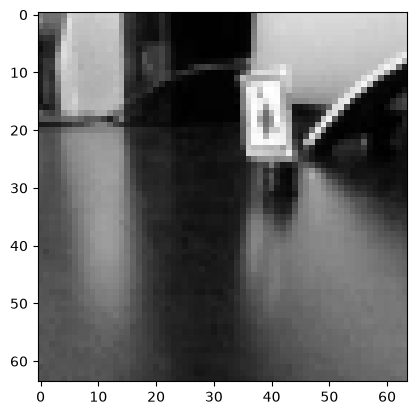

In [419]:
plt.imshow(data_setROI[10][0], cmap="gray")